# Scarlett Particle Tagging — main plots

A simulation-first study of how light scattered by small particles can be
used to estimate their **diameter, refractive index, concentration and
motion** in a controlled laboratory sample.

**Everything in this notebook is model output or synthetic data. Nothing was
measured.** The "truth" values are choices made in `scarlett.synthetic`.

| Part | Content |
|---|---|
| 1 | The SEALS wavelength-to-angle map (figures 1–2 of the original `main.m`) |
| 2 | Mie scattering: irradiance, polarization, phase (figures 3–6) |
| 3 | Size parameter and the Rayleigh / Rayleigh-Debye / Mie regimes |
| 4 | Cross section and wavelength dependence |
| 5 | Diameter uncertainty: `dia ± uncertainty` |
| 6 | Sensor chain: photodiode, transimpedance amplifier, ADC |
| 7 | Estimating diameter and concentration, with confidence intervals |
| 8 | Motion from the intensity autocorrelation |
| 9 | Fixed-point (ASIC-style) estimator and the RF telemetry packet |

> **If the particle diameter worries you:** diameter is simply a model
> parameter. We do not need to know it perfectly at first. We can test a
> range of possible diameters and study how the predicted signal changes.
> Part 5 does exactly that, and Part 7 turns it around: it tries many
> diameters and keeps the ones the data cannot rule out.

In [1]:
import sys
from pathlib import Path

src = Path.cwd().parent / "src"              # lets the notebook run without installing the package
if src.is_dir() and str(src) not in sys.path:
    sys.path.insert(0, str(src))

import numpy as np
import matplotlib.pyplot as plt

import scarlett
from scarlett import physics as ph, sensor as se, estimator as es
from scarlett import asic, telemetry as tm, synthetic as sy, visualization as viz

SEED = sy.DEFAULT_SEED
P = ph.SEALS_DEFAULTS                         # default values of the original main.m, in SI units
LAM0 = 0.5 * (P["lam_min"] + P["lam_max"])
plt.rcParams["figure.dpi"] = 90
print("scarlett", scarlett.__version__, "| seed", SEED)
print(f"default particle: dia = {P['dia']*1e6:.2f} um, npar = {P['npar']}, nmed = {P['nmed']}, "
      f"wavelength {P['lam_min']*1e9:.0f}-{P['lam_max']*1e9:.0f} nm")

scarlett 0.1.0 | seed 0
default particle: dia = 9.94 um, npar = 1.39, nmed = 1.0, wavelength 1580-1600 nm


## 1. SEALS: one wavelength, one angle

Two gratings spread a broadband pulse into a rainbow; an objective lens
focuses it so that each wavelength reaches the particle from its own angle.
A single detector at a fixed angle then sees a spectrum that *is* the angular
scattering pattern. With the detector at `measurement_angle` = 20°, the
scattering angle is the illumination angle plus 20°.

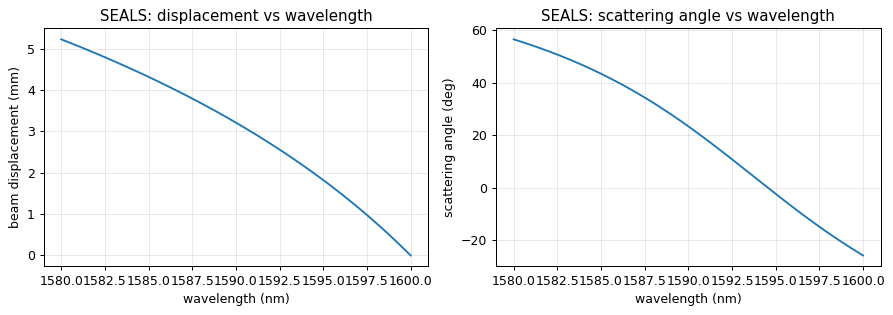

beam displacement: 5.228 mm at 1580 nm, 0.000 mm at 1600 nm (paper Fig. 2: about 5.3 mm to 0)
illumination angle: +36.5 deg to -45.8 deg


In [2]:
fig = viz.plot_seals_map(); plt.show()
lam = np.linspace(P["lam_min"], P["lam_max"], P["n_wavelengths"])
y, theta_illum = ph.seals_wavelength_to_angle(P["groove_spacing"], P["grating_distance"], P["grating_angle"],
                                              P["dcorr"], P["pupil_diameter"], P["numerical_aperture"], lam)
print(f"beam displacement: {y[0]*1e3:.3f} mm at {lam[0]*1e9:.0f} nm, {y[-1]*1e3:.3f} mm at {lam[-1]*1e9:.0f} nm "
      "(paper Fig. 2: about 5.3 mm to 0)")
print(f"illumination angle: {np.degrees(theta_illum[0]):+.1f} deg to {np.degrees(theta_illum[-1]):+.1f} deg")

## 2. Mie scattering

For a homogeneous sphere the scattered field is described by two complex
amplitudes, $S_1(\theta)$ (perpendicular to the scattering plane) and
$S_2(\theta)$ (parallel). With incident irradiance $I_0$ and
$k=2\pi n_{\text{med}}/\lambda$:

$$I_\perp=I_0\frac{|S_1|^2}{k^2r^2},\qquad I_\parallel=I_0\frac{|S_2|^2}{k^2r^2},\qquad
I_{\text{unpolarized}}=\tfrac12(I_\parallel+I_\perp).$$

The original `main.m` plotted $I_\parallel+I_\perp$, which is twice the
unpolarized irradiance. The Rayleigh-Debye curve is shown for comparison; it
is far outside its valid range for this particle.

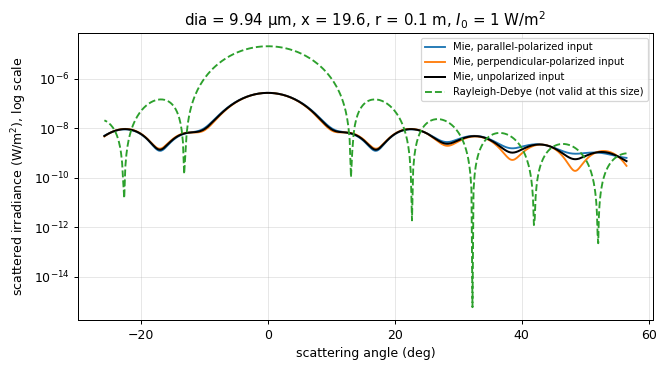

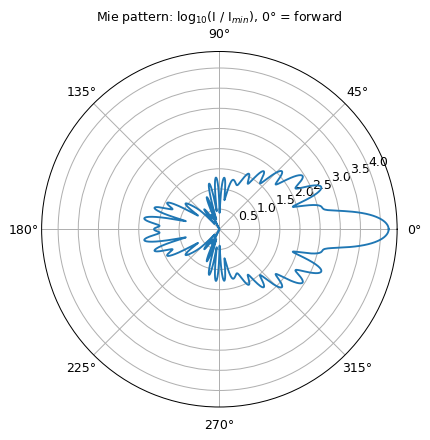

In [3]:
viz.plot_angular_pattern(); plt.show()
viz.plot_polar_pattern(); plt.show()

**Wavelength axis and phase.** Multiplying the pattern by the source spectrum
gives what a spectrometer would record. The left panel also shows the
original code's lineshape, which was applied back to front; the difference is
small here only because the default source is centred. The phase is wrapped
to ±180° and contains the common factor $e^{ikr}$.

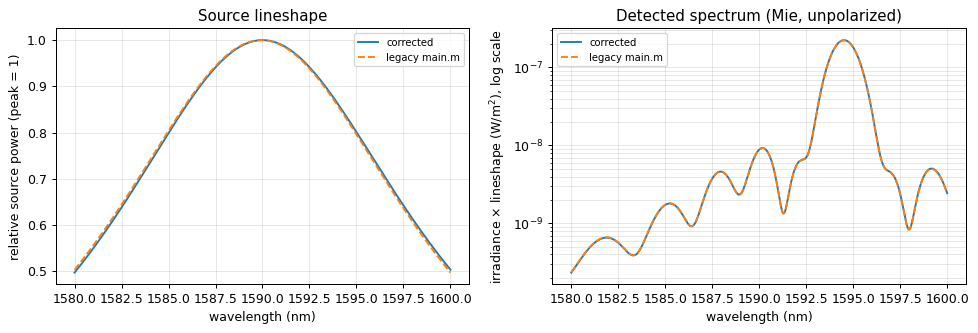

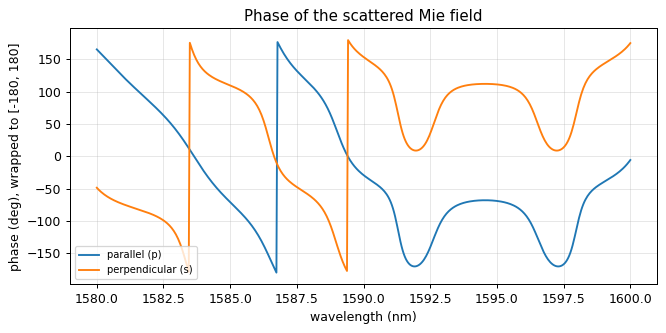

In [4]:
viz.plot_wavelength_response(); plt.show()
viz.plot_phase(); plt.show()

## 3. Size parameter and regimes

$$x=\frac{\pi\,\text{dia}}{\lambda/n_{\text{med}}}$$

is the circumference of the particle in units of the wavelength inside the
medium. It decides which model is trustworthy.

| Regime | Condition | Cross section |
|---|---|---|
| Rayleigh | $x\ll1$ | $\propto \text{dia}^6/\lambda^4$ |
| Rayleigh-Debye | $\lvert m-1\rvert\ll1$ and $2x\lvert m-1\rvert\ll1$ | dipoles interfering across the volume |
| Mie | any $x$ (homogeneous sphere) | exact multipole sum |

  diameter        x          regime   Q_sca Mie  Rayleigh/Mie  R-Debye/Mie
      20nm    0.040        rayleigh   3.654e-07         1.000        0.999
     100nm    0.198        rayleigh   2.282e-04         1.001        0.985
     500nm    0.988             mie   1.259e-01         1.134        0.781
    2000nm    3.952             mie   3.466e+00        10.542        0.989
    9940nm   19.640             mie   2.113e+00     10549.174       45.710


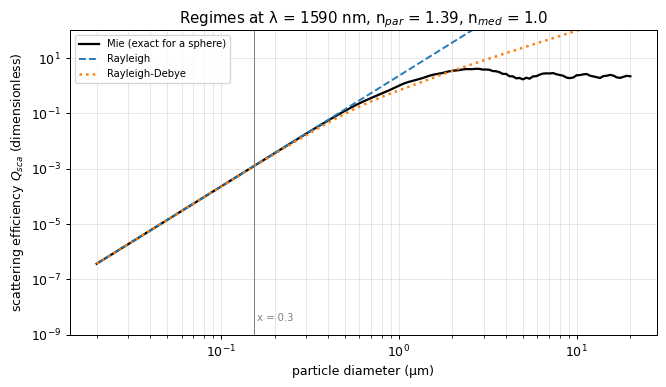

In [5]:
print(f"{'diameter':>10} {'x':>8} {'regime':>15} {'Q_sca Mie':>11} {'Rayleigh/Mie':>13} {'R-Debye/Mie':>12}")
for dia in (20e-9, 100e-9, 500e-9, 2e-6, 9.94e-6):
    x = ph.size_parameter(dia, LAM0, P["nmed"])
    mie = ph.mie_cross_section(P["npar"], P["nmed"], dia, LAM0)
    ray = ph.rayleigh_cross_section(dia, LAM0, P["nmed"], P["npar"])
    rdg = ph.rayleigh_debye_cross_section(dia, LAM0, P["nmed"], P["npar"])
    print(f"{dia*1e9:>8.0f}nm {x:>8.3f} {ph.regime(dia, LAM0, P['npar'], P['nmed']):>15} "
          f"{mie/(np.pi*dia**2/4):>11.3e} {ray/mie:>13.3f} {rdg/mie:>12.3f}")
viz.plot_regimes(P["npar"], P["nmed"], LAM0); plt.show()

Rayleigh and Mie agree for the smallest particles and separate once $x$
approaches 1; by $x\approx20$ Rayleigh overestimates by four orders of
magnitude. Rayleigh-Debye is not reliable here either, because $m=1.39$ is
not close to 1: its near-agreement at 2 µm is a coincidence, and at 9.94 µm
it is off by a factor of about 46.

## 4. Cross section and wavelength dependence

Small particles follow $\lambda^{-4}$ (the reason the sky is blue). Large
particles do not: their cross section is of the order of twice their
geometric area and oscillates with wavelength.

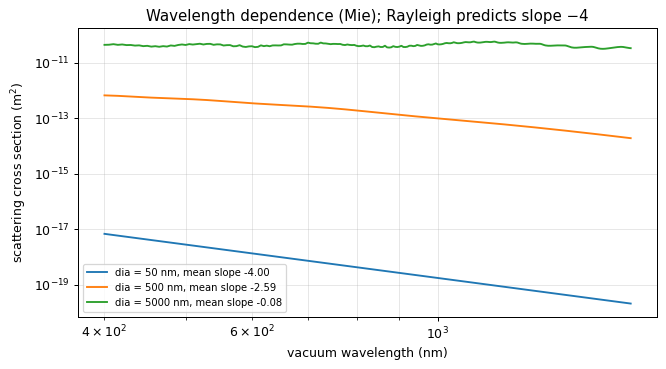

default particle: sigma_sca = 1.6400e-10 m^2 = 2.113 x geometric area


In [6]:
viz.plot_cross_section_vs_wavelength(); plt.show()
sigma = ph.mie_cross_section(P["npar"], P["nmed"], P["dia"], LAM0)
print(f"default particle: sigma_sca = {sigma:.4e} m^2 = {sigma/(np.pi*P['dia']**2/4):.3f} x geometric area")

## 5. Diameter uncertainty: `dia ± uncertainty`

We do not need the diameter in advance. Sweep it and watch the prediction
move. The band on the left is the pattern for every diameter within ±2 %.
The right panel is the relative sensitivity
$(\text{dia}/I)\,\partial I/\partial\text{dia}$: where it is large, a small
change in diameter makes a large change in signal, and those angles carry the
size information.

The printed RMS change is not monotonic in the diameter step. Near the deep
minima of the pattern a small shift of a lobe changes the ratio enormously,
so a relative measure saturates quickly. The lesson is that this pattern is
very sensitive to diameter, at the level of a fraction of a percent.

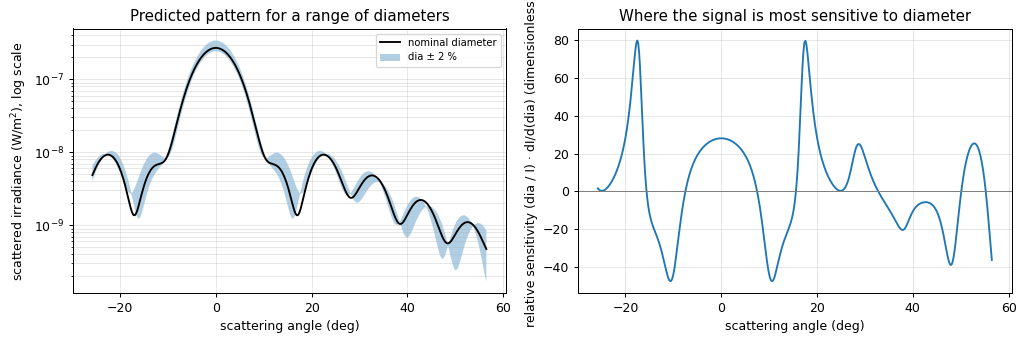

RMS relative change of the pattern over the measured angles:
   dia +  0.1 %  ->     3.1 %
   dia +  0.5 %  ->    29.7 %
   dia +  1.0 %  ->    23.9 %
   dia +  2.0 %  ->    30.4 %
   dia +  5.0 %  ->    80.6 %


In [7]:
viz.plot_diameter_sensitivity(rel_uncertainty=0.02); plt.show()

theta = theta_illum + P["measurement_angle"]
pattern = lambda d: ph.mie_scattering(P["npar"], P["nmed"], d, LAM0, theta, P["r"]).i_unpolarized
nominal = pattern(P["dia"])
print("RMS relative change of the pattern over the measured angles:")
for rel in (0.001, 0.005, 0.01, 0.02, 0.05):
    change = np.sqrt(np.mean((pattern(P["dia"] * (1 + rel)) / nominal - 1) ** 2))
    print(f"   dia + {100*rel:4.1f} %  ->  {100*change:6.1f} %")

## 6. Sensor chain (synthetic)

From here on the sample is a simulated dilute suspension in water
(`scarlett.synthetic.SampleTruth`): 5 µm beads, index 1.57, 20 particles in a
1 nL probe volume. The scattered power per angle channel goes through

`photodiode → transimpedance amplifier → programmable gain → anti-alias filter → ADC`.

Forward scattering is far brighter than side scattering, so a spectral
**equalization filter** (the SEALS paper's idea) attenuates the wavelengths
that map to bright angles. The grey band marks channels within 5° of the
forward direction, which would see the unscattered beam and are not used.

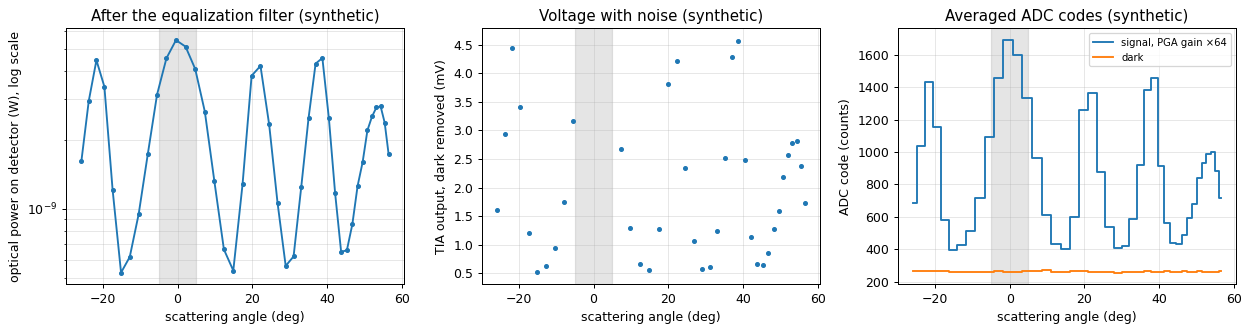

PGA gain x64, ADC 12 bit, LSB 244 uV, fs = 100 kHz, anti-alias 40 kHz, clipped: False
noise per sample (photodiode current): shot 8.09e-12 A, thermal 3.19e-11 A, amplifier 2.51e-11 A, total 4.14e-11 A
noise floor: 4.08e-11 W;  mean signal 2.25e-09 W = 1.80e+10 photons/s


In [8]:
data = sy.generate_dataset(seed=SEED)
bench, sensor, scan, dark = data["bench"], data["sensor"], data["scan"], data["dark"]
viz.plot_sensor_chain(data); plt.show()

noise = se.noise_current(sensor.responsivity * scan["power_w"].mean(), sensor)
print(f"PGA gain x{scan['gain']}, ADC {sensor.adc_bits} bit, LSB {sensor.lsb*1e6:.0f} uV, "
      f"fs = {sensor.sampling_rate/1e3:.0f} kHz, anti-alias {sensor.antialias_cutoff/1e3:.0f} kHz, "
      f"clipped: {bool(scan['clipped'].any())}")
print(f"noise per sample (photodiode current): shot {float(noise['shot']):.2e} A, "
      f"thermal {noise['thermal']:.2e} A, amplifier {noise['amplifier']:.2e} A, total {float(noise['total']):.2e} A")
print(f"noise floor: {se.noise_floor_power(sensor):.2e} W;  mean signal {scan['power_w'].mean():.2e} W "
      f"= {se.photon_rate(scan['power_w'].mean(), bench.lam_center):.2e} photons/s")

## 7. Estimating diameter and concentration

The estimator tries every diameter in a lookup table. For each candidate the
best particle count has a closed form, and the candidate with the smallest
$\chi^2$ wins; the diameter is then refined between grid points. The 95 %
interval is the range of diameters with $\chi^2-\chi^2_{\min}\le3.84$.

The uncertainty used in the fit is the electronic noise **plus a 2 %
allowance** for what the model does not know exactly. The synthetic data
contain a matching 2 % channel-to-channel ripple.

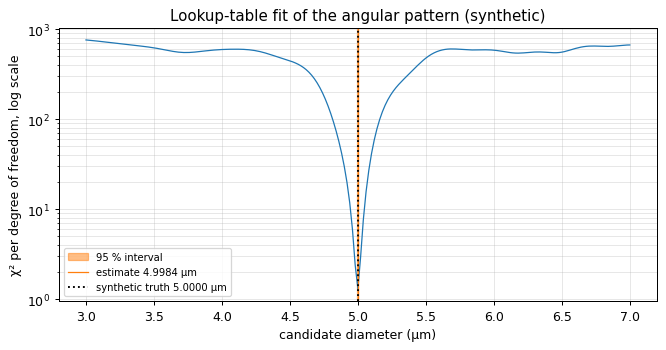

diameter      : 4.9984 um, 95 % interval [4.9928, 5.0039] um   (synthetic truth 5.0000)
particles     : 19.91 +/- 0.07   (truth 20)
concentration : 1.991e+13 per m^3   (truth 2.000e+13)
chi2/dof = 46.9/36, fit probability 0.11, ambiguous: False
Cramer-Rao bound: 2.9 nm (1 sigma)


In [9]:
lut = es.build_lookup_table(np.arange(3.0e-6, 7.0e-6 + 1e-12, 20e-9), [data["truth"]["npar"]], bench, sensor)
volts = scan["volts"] - dark["volts"]
sigma = es.combined_sigma(volts, np.hypot(scan["sigma_volts"], dark["sigma_volts"]), rel_uncertainty=0.02)
est = es.estimate_particle(volts, sigma, lut, bench, sensor, channel_ok=~scan["clipped"])

truth = data["truth"]
viz.plot_estimate(lut, est, truth["dia"]); plt.show()
print(f"diameter      : {est.dia*1e6:.4f} um, 95 % interval [{est.dia_ci[0]*1e6:.4f}, {est.dia_ci[1]*1e6:.4f}] um"
      f"   (synthetic truth {truth['dia']*1e6:.4f})")
print(f"particles     : {est.n_particles:.2f} +/- {est.n_particles_sigma:.2f}   (truth {scan['n_particles_true']:.0f})")
print(f"concentration : {est.concentration:.3e} per m^3   (truth {truth['concentration']:.3e})")
print(f"chi2/dof = {est.chi2:.1f}/{est.dof}, fit probability {est.fit_probability:.2f}, ambiguous: {est.ambiguous}")
crb = es.diameter_cramer_rao(truth["dia"], truth["npar"], est.n_particles, sigma, bench, sensor)
print(f"Cramer-Rao bound: {crb*1e9:.1f} nm (1 sigma)")

**Read this precision with care.** A few nanometres on a 5 µm particle is
what the *noise* allows **if** the particle is a perfect homogeneous sphere of
known refractive index and the angles are known exactly. The interval says
nothing about those assumptions. On real samples, shape, index and alignment
errors would dominate.

## 8. Motion: Brownian diffusion

With coherent light the scattered intensity flickers as the particles
diffuse. The intensity autocorrelation decays as
$g_2(\tau)-1=\beta e^{-2\Gamma\tau}$ with $\Gamma=Dq^2$, and Stokes-Einstein
converts the diffusion coefficient $D$ into a hydrodynamic diameter. This is
an independent, much coarser size estimate.

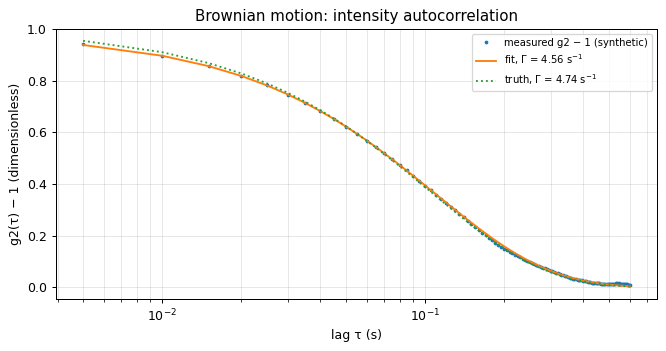

decay rate            : 4.68 1/s, 95 % interval [4.35, 5.02]   (truth 4.74)
diffusion coefficient : 8.475e-14 m^2/s
hydrodynamic diameter : 5.06 um, 95 % interval [4.72, 5.45] um   (truth 5.00)


In [10]:
motion = es.estimate_motion(data["dls_counts"], data["dls_dt_s"], bench.lam_center, bench.nmed,
                            data["dls_theta_rad"], max_lag=120,
                            temperature=truth["temperature"], viscosity=truth["viscosity"])
viz.plot_motion(data["dls_counts"], data["dls_dt_s"], 120, data["dls_decay_rate_true_per_s"]); plt.show()
print(f"decay rate            : {motion['decay_rate']:.2f} 1/s, 95 % interval "
      f"[{motion['decay_rate_ci'][0]:.2f}, {motion['decay_rate_ci'][1]:.2f}]   (truth {data['dls_decay_rate_true_per_s']:.2f})")
print(f"diffusion coefficient : {motion['diffusion']:.3e} m^2/s")
print(f"hydrodynamic diameter : {motion['hydrodynamic_dia']*1e6:.2f} um, 95 % interval "
      f"[{motion['hydrodynamic_dia_ci'][0]*1e6:.2f}, {motion['hydrodynamic_dia_ci'][1]*1e6:.2f}] um"
      f"   (truth {truth['dia']*1e6:.2f})")

## 9. ASIC-style estimator and telemetry (architecture proposal)

**No chip exists.** `scarlett.asic` is a behavioural model of the arithmetic a
proposed digital block would do: integer ADC sums, 16-bit templates from
calibration memory, a correlator bank. Its resolution is the lookup-table
step. The RF layer only carries the result: a tag ID for the sample
container, a timestamp, the estimate and its interval.

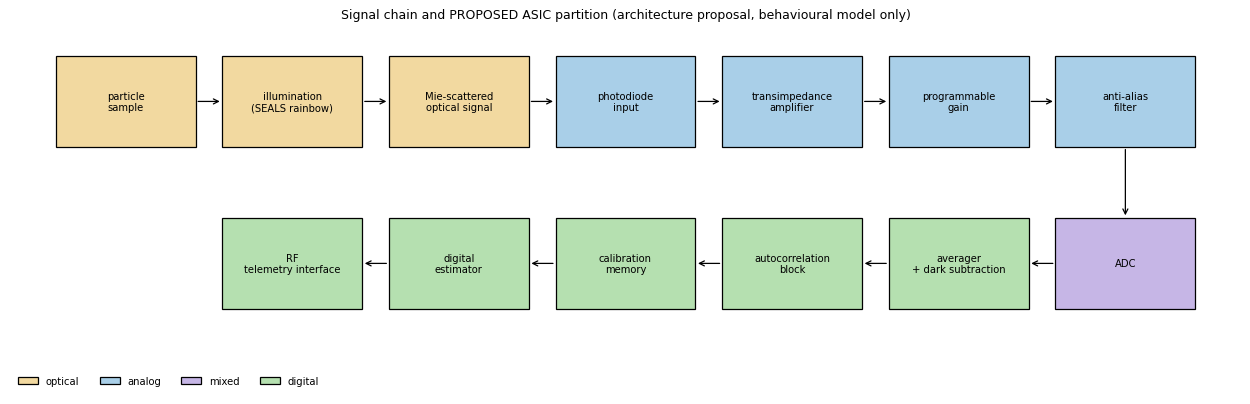

fixed-point estimate : 5.000 um, accepted range [5.000, 5.000] um (table step 0.020 um)
floating-point ref.  : 4.9984 um
largest measurement value 19153 fits in 20 bits; 201 templates x 38 channels x 16 bit = 14.9 kB of calibration memory

telemetry packet (42 bytes): 53500100771ea45ce80300000000000086130000811300008c13000022065f0032e3905565d8be29142d
decoded: tag 0x5CA41E77, dia 4.998 um [4.993, 5.004], npar 1.57, 1.991e+13 per m^3
simulated free-space link at 5 m: path loss 54.2 dB, Eb/N0 55.8 dB


In [11]:
viz.plot_block_diagram(); plt.show()

memory = asic.build_calibration_memory(lut, dark["code_sums"], scan["gain"], sensor)
meas = asic.subtract_dark(scan["code_sums"], memory)
sigma_counts = float(np.sqrt(np.mean(sigma[lut.mask] ** 2)) * scan["gain"] * sensor.samples_per_channel / sensor.lsb)
fixed = asic.fixed_point_estimate(meas, memory.templates_q15, sigma_counts)
k = fixed["best_index"]
print(f"fixed-point estimate : {lut.dia[k]*1e6:.3f} um, accepted range "
      f"[{lut.dia[fixed['ci_lo_index']]*1e6:.3f}, {lut.dia[fixed['ci_hi_index']]*1e6:.3f}] um (table step 0.020 um)")
print(f"floating-point ref.  : {est.dia*1e6:.4f} um")
print(f"largest measurement value {np.abs(meas).max()} fits in {asic.AsicConfig().measurement_bits} bits; "
      f"{memory.templates_q15.shape[0]} templates x {memory.templates_q15.shape[1]} channels x 16 bit "
      f"= {memory.templates_q15.size*2/1024:.1f} kB of calibration memory")

report = tm.TagReport(tag_id=truth["tag_id"], timestamp_ms=1000, dia=est.dia, dia_ci=est.dia_ci, npar=est.npar,
                      confidence_level=est.confidence_level, concentration=est.concentration,
                      diffusion=motion["diffusion"])
packet = tm.encode_packet(report)
link = tm.link_budget(distance=5.0)
decoded = tm.decode_packet(tm.transmit(packet, link["bit_error_rate"], np.random.default_rng(SEED)))
print(f"\ntelemetry packet ({len(packet)} bytes): {packet.hex()}")
print(f"decoded: tag 0x{decoded.tag_id:08X}, dia {decoded.dia*1e6:.3f} um "
      f"[{decoded.dia_ci[0]*1e6:.3f}, {decoded.dia_ci[1]*1e6:.3f}], npar {decoded.npar}, "
      f"{decoded.concentration:.3e} per m^3")
print(f"simulated free-space link at 5 m: path loss {link['path_loss_db']:.1f} dB, Eb/N0 {link['ebn0_db']:.1f} dB")

## What this notebook does not claim

- No experimental result. Every dataset here is synthetic.
- No fabricated or circuit-level ASIC. The ASIC section is an architecture
  proposal with a behavioural model.
- No measurement accuracy for real particles. The confidence intervals cover
  noise under a perfect-sphere, known-index model.
- No radio on a particle, no tracking, no surveillance. The tag labels a
  sample container on a bench.
- No reproduction of the paper's measured curves. Only its analytic
  wavelength-to-angle map is reproduced.

See the README for the full list.